Anggota Kelompok:

Maydian Ratu Valencia (25031554121)

Faris Riky Pratam (25031554176)

Dalilah Putri Rahma (25031554239)

# Persiapan

In [9]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA


def route(nama):
    for dirpath, _, filenames in os.walk('data/'):
        if nama in filenames:
            return os.path.join(dirpath, nama)

class CFG:
    SEED = 42
    nama_data = 'Online_Retail.xlsx'

In [10]:
df = pd.read_excel(route(CFG.nama_data))

# Tahapan 1

## Dataset Online Retail (UCI Machine Learning Repository)

### 1. Sumber Dataset

| Atribut | Keterangan |
|---|---|
| **Nama Dataset** | Online Retail |
| **Repositori** | UCI Machine Learning Repository (ID: 352) |
| **Pembuat/Donatur** | Daqing Chen, School of Engineering, London South Bank University |
| **Tanggal Donasi** | 5 November 2015 |
| **DOI** | [10.24432/C5BW33](https://doi.org/10.24432/C5BW33) |
| **Lisensi** | Creative Commons Attribution 4.0 International (CC BY 4.0) |
| **Format File** | `Online Retail.xlsx` (±22,6 MB) |
| **Karakteristik** | Multivariate, Sequential, Time-Series |
| **Area Subjek** | Bisnis |
| **Tugas Terkait** | Classification, Clustering |

**Deskripsi singkat:** Dataset ini berisi data transaksi yang terjadi antara **1 Desember 2010 dan 9 Desember 2011** dari sebuah perusahaan ritel *online* tanpa toko fisik yang terdaftar di Inggris (UK). Perusahaan ini terutama menjual hadiah unik untuk berbagai acara, dan banyak pelanggannya adalah **pedagang grosir (wholesaler)**.

**Sitasi (APA):**
> Chen, D. (2015). *Online Retail* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33

**Makalah pengantar:** Chen, D., Sain, S. L., & Guo, K. (2012). *Data mining for the online retail industry: A case study of RFM model-based customer segmentation using data mining.* Journal of Database Marketing and Customer Strategy Management, 19(3).

**Tautan:** https://archive.ics.uci.edu/dataset/352/online+retail

---

### 2. Konteks Permasalahan: Segmentasi Pelanggan (Customer Segmentation)

#### Latar Belakang
Pada bisnis ritel *online*, pelanggan memiliki perilaku belanja yang sangat beragam. Ada yang sering membeli dalam jumlah besar, ada yang hanya sekali membeli, dan ada pula yang sudah lama tidak aktif. Memperlakukan semua pelanggan dengan strategi pemasaran yang sama tidak efisien.

#### Tujuan
Mengelompokkan pelanggan ke dalam **segmen-segmen yang homogen** berdasarkan perilaku transaksinya, sehingga perusahaan dapat:
- Menyusun strategi pemasaran yang dipersonalisasi untuk tiap segmen
- Mengidentifikasi pelanggan bernilai tinggi (*loyal/VIP customers*)
- Mendeteksi pelanggan yang berisiko berhenti (*churn*)
- Mengalokasikan anggaran promosi dan retensi dengan lebih efisien

#### Pendekatan: Model RFM + Clustering
Makalah pengantar dataset ini menggunakan model **RFM** dan *data mining* (misalnya K-Means) untuk segmentasi. Ketiga dimensi RFM diturunkan dari data transaksi:

| Dimensi | Arti | Cara Penurunan dari Dataset |
|---|---|---|
| **Recency (R)** | Seberapa baru pelanggan terakhir bertransaksi | Selisih tanggal acuan dengan `InvoiceDate` terakhir per `CustomerID` |
| **Frequency (F)** | Seberapa sering pelanggan bertransaksi | Jumlah `InvoiceNo` unik per `CustomerID` |
| **Monetary (M)** | Total nilai belanja pelanggan | Jumlah dari `Quantity × UnitPrice` per `CustomerID` |

Hasil RFM kemudian dapat di-*cluster* menggunakan algoritma seperti **K-Means**, **Hierarchical Clustering**, atau **DBSCAN** untuk membentuk segmen pelanggan.

---

### 3. Jumlah Observasi

| Item | Jumlah |
|---|---|
| **Jumlah Instances (baris)** | **541.909** |
| **Jumlah Features** | 6 (menurut UCI; total kolom pada tabel variabel adalah 8, termasuk 2 kolom ber-role ID) |
| **Periode Data** | 01/12/2010 – 09/12/2011 |
| **Missing Values** | Tertulis "No" pada halaman UCI |

---

### 4. Fitur yang Digunakan

#### Daftar Variabel

| Variabel | Role | Tipe | Deskripsi | Satuan |
|---|---|---|---|---|
| `InvoiceNo` | ID | Kategorikal | Nomor faktur 6 digit yang unik untuk tiap transaksi. Jika diawali huruf **'C'**, berarti **pembatalan** | – |
| `StockCode` | ID | Kategorikal | Kode produk 5 digit yang unik untuk tiap produk | – |
| `Description` | Feature | Kategorikal | Nama produk | – |
| `Quantity` | Feature | Integer | Jumlah tiap produk per transaksi | unit |
| `InvoiceDate` | Feature | Date | Tanggal dan waktu transaksi dibuat | – |
| `UnitPrice` | Feature | Continuous | Harga per unit produk | Poundsterling (£) |
| `CustomerID` | Feature | Kategorikal | Nomor pelanggan 5 digit yang unik untuk tiap pelanggan | – |
| `Country` | Feature | Kategorikal | Nama negara tempat pelanggan berdomisili | – |

#### Fitur yang Relevan untuk Segmentasi Pelanggan

**Fitur utama (untuk membangun RFM):**
- `CustomerID`: kunci agregasi, satu baris hasil = satu pelanggan
- `InvoiceNo`: menghitung **Frequency**
- `InvoiceDate`: menghitung **Recency**
- `Quantity` dan `UnitPrice`: menghitung **Monetary** (`TotalPrice = Quantity × UnitPrice`)

**Fitur yang Digunakan:**
- `Recency`: Seberapa lama sejak transaksi terakhir
- `Frequency`: Seberapa sering customer bertransaksi
- `Monetary`: Total uang yang dikeluarkan

---

### Ringkasan

| Aspek | Ringkasan |
|---|---|
| **Sumber** | UCI ML Repository, Daqing Chen (London South Bank University), CC BY 4.0 |
| **Domain** | Ritel online di UK, menjual hadiah, banyak pelanggan grosir |
| **Periode** | 1 Des 2010 – 9 Des 2011 |
| **Observasi** | 541.909 baris transaksi |
| **Masalah** | Segmentasi pelanggan berbasis RFM dan clustering |
| **Fitur kunci** | `CustomerID`, `InvoiceNo`, `InvoiceDate`, `Quantity`, `UnitPrice` |


In [11]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [12]:
overview = pd.DataFrame({
    'column_name': df.columns.values,
    'data_type': df.dtypes.values,
    'missing_value(%)': df.isna().mean().values * 100,
    'negative_value(%)': [len(df[col][df[col] < 0]) / df.shape[0] * 100 if col in df.select_dtypes(include=[np.number]).columns else 0 for col in df.columns],
    'duplicates': df.duplicated().sum(),
    'unique': df.nunique().values,
    'value': [df[col].unique() for col in df.columns]
})
display(overview)

,column_name,data_type,missing_value(%),negative_value(%),duplicates,unique,value
0,InvoiceNo,object,0.000000,0.000000,5268,25900,"[536365, 536366, 536367, 536368, 536369, 53637..."
1,StockCode,object,0.000000,0.000000,5268,4070,"[85123A, 71053, 84406B, 84029G, 84029E, 22752,..."
2,Description,object,0.268311,0.000000,5268,4223,"[WHITE HANGING HEART T-LIGHT HOLDER, WHITE MET..."
3,Quantity,int64,0.000000,1.960477,5268,722,"[6, 8, 2, 32, 3, 4, 24, 12, 48, 18, 20, 36, 80..."
4,InvoiceDate,datetime64[ns],0.000000,0.000000,5268,23260,"[2010-12-01 08:26:00, 2010-12-01 08:28:00, 201..."
5,UnitPrice,float64,0.000000,0.000369,5268,1630,"[2.55, 3.39, 2.75, 7.65, 4.25, 1.85, 1.69, 2.1..."
6,CustomerID,float64,24.926694,0.000000,5268,4372,"[17850.0, 13047.0, 12583.0, 13748.0, 15100.0, ..."
7,Country,object,0.000000,0.000000,5268,38,"[United Kingdom, France, Australia, Netherland..."


## Handle Missing, Negative, and Invalid Data

Pada tahap ini, dilakukan penanganan data hilang (*missing values*) dan data bernilai negatif (*negative values*). Penanganan data negatif dilakukan dengan mengubah nilai negatif menjadi nilai absolut menggunakan fungsi `abs()` pada fitur Quantity dan UnitPrice. Selain itu, baris data yang tidak memiliki CustomerID dihapus dari DataFrame karena identitas pelanggan diperlukan dalam proses pengelompokan transaksi dan perhitungan fitur RFM.

In [13]:
# Handle Negative Value
df['Quantity'] = df['Quantity'].abs()
df['UnitPrice'] = df['UnitPrice'].abs()

df['Amount'] = df['Quantity'] * df['UnitPrice']
df['Date'] = df['InvoiceDate'].dt.date
df['Time'] = df['InvoiceDate'].dt.time

# Handle Missing Value
df = df.dropna(subset=['CustomerID'])

# Sorting
df = df.sort_values(by=['CustomerID'])

## Feature Engineering

In [14]:
today = df['InvoiceDate'].max()
df['Recency'] = (today - df['InvoiceDate']).dt.days

rfm = df.groupby('CustomerID').agg({
    'Recency': 'min',
    'InvoiceNo': 'count',
    'Amount': 'sum'
}).rename(columns={
    'InvoiceNo': 'Frequency',
    'Amount': 'Monetary'
})

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,325,2,154367.20
12347.0,1,182,4310.00
12348.0,74,31,1797.24
12349.0,18,73,1757.55
12350.0,309,17,334.40


## Handle Outlier

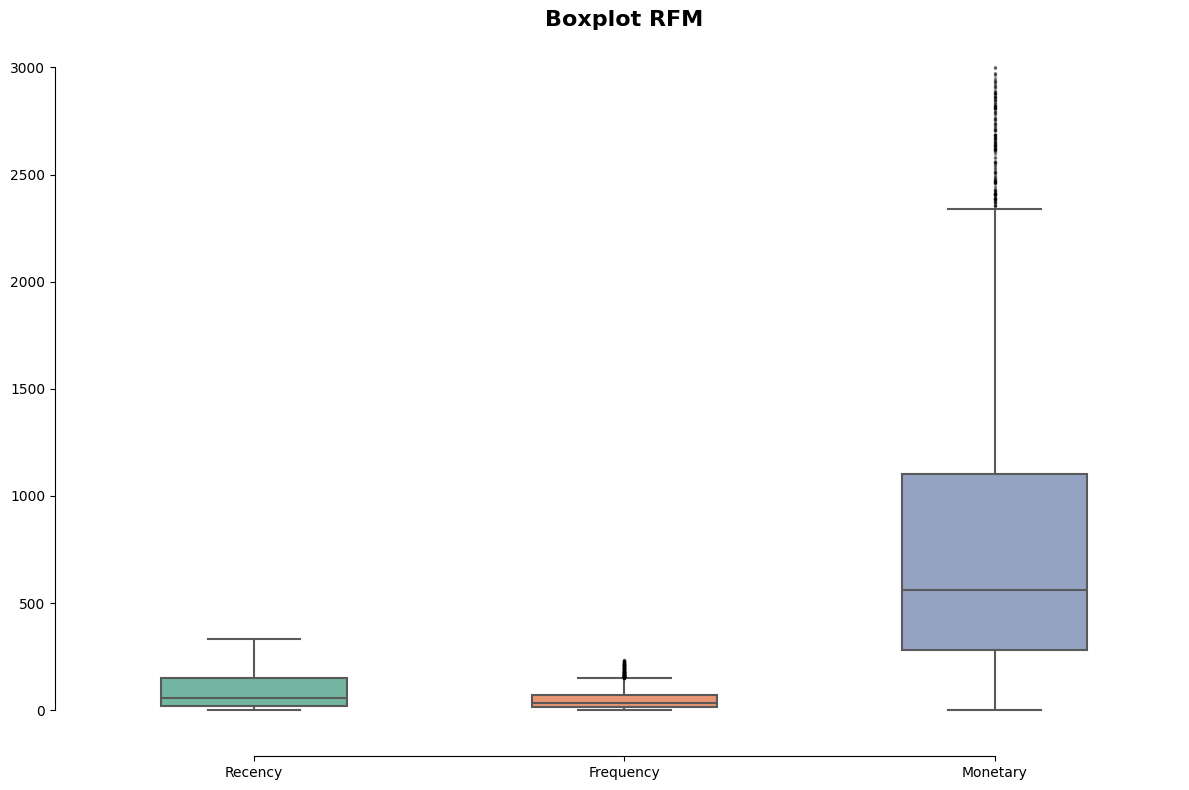

In [19]:
cols = ['Recency', 'Frequency', 'Monetary']
plt.figure(figsize=(12, 8))
ax = sns.boxplot(
    data=rfm[cols], palette=sns.color_palette("Set2", 3),
    width=0.5, linewidth=1.5,
    flierprops=dict(
        marker='.', markersize=3, alpha=0.3,
        markerfacecolor='black', markeredgecolor='black'
    )
)
ax.set_title("Boxplot RFM", fontsize=16, weight="bold")
sns.despine(offset=10, trim=True)
plt.tight_layout()
plt.show()

In [16]:
def handle_outlier(data, col):
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)

    iqr = Q3 - Q1
    lower_bound = Q1 - 1.5 * iqr
    upper_bound = Q3 + 1.5 * iqr

    condition = (data[col] < lower_bound) | (data[col] > upper_bound)
    outlier = data[condition]
    print('Amount of Outlier:')
    print(outlier[col].count())

    no_outlier = data[~condition]

    return no_outlier.reset_index(drop=True)

for col in ['Recency', 'Frequency', 'Monetary']:
    rfm = handle_outlier(rfm, col)

Amount of Outlier:
149
Amount of Outlier:
373
Amount of Outlier:
313


## Feature Scaling & Dimensionality Reduction

Pada tahap ini, dilakukan proses standardisasi data menggunakan metode StandardScaler untuk menyamakan skala antarfitur sehingga setiap fitur memiliki kontribusi yang seimbang dalam proses clustering. Standardisasi dilakukan dengan mengubah nilai setiap fitur agar memiliki rata-rata (mean) sebesar 0 dan standar deviasi sebesar 1. Dengan demikian, perbedaan rentang nilai antarfitur RFM dapat diminimalkan sehingga tidak ada fitur yang mendominasi proses pengelompokan akibat perbedaan skala data.

In [17]:
cluster_cols = ['Recency', 'Frequency', 'Monetary']
X = rfm[cluster_cols].copy()

preprocessor = Pipeline(
    [
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=2, random_state=42))
    ]
)

X_scaled = pd.DataFrame(preprocessor.fit_transform(X), columns=['PCA_1', 'PCA_2'])

# Tahap 2

In [18]:
class SOM:
  def __init__(self, baris=20, kolom=20, learning_rate=.5, sigma=None, epochs=20, seed=1):
    self.baris = baris
    self.kolom = kolom
    self.learning_rate = learning_rate
    self.sigma = sigma
    self.seed = seed

  def fit(self, X):
    generate_angka_random = np.random.default_generate_angka_random(self.seed)
    jumlah_baris, jumlah_kolom = X.shape
    self.bobot = generate_angka_random.uniform(X.min(axis=0), X.max(axis=0), (self.baris, self.kolom, jumlah_kolom))
    if self.sigma is None:
      self.sigma = max(self.baris, self.kolom) / 2
    grid = np.array([posisi_baris, posisi_kolom]
                    for posisi_baris in range(self.baris)
                    for posisi_kolom in range(self.kolom))
    total = self.epochs * jumlah_baris
    for langkah in range(total):
      x = X[generate_angka_random.integers(jumlah_baris)]
      progres = langkah / max(total -1, 1)
      learning_rate = self.learning_rate * (1 - progres)
      sigma = max(.5, self.sigma * (1 - progres))

      dist